# Exploratory analysis: where does the credit risk sit?

30,000 credit card customers, monthly statements Apr to Sep 2005, default measured in Oct 2005.
This notebook works on the SQL Server analytics layer (`sql/03_analytics_views.sql`), so the definitions
(utilisation, payment ratio, delinquency) are the same ones Power BI and the model use.

Questions:
1. Which segments carry more risk?
2. How does repayment behaviour change in the months before default?
3. What in the data needs care before modelling?

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True, "font.size": 10,
})
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
engine = create_engine(URL.create(
    "mssql+pyodbc",
    host=os.getenv("SQL_SERVER", r"localhost\SQLEXPRESS"),
    database=os.getenv("SQL_DATABASE", "CreditRiskDB"),
    query={"driver": "ODBC Driver 18 for SQL Server", "trusted_connection": "yes",
           "TrustServerCertificate": "yes"},
))


def sql(query):
    return pd.read_sql(query, engine)

In [2]:
profile = sql("SELECT * FROM analytics.vw_customer_profile")
monthly = sql("SELECT * FROM analytics.vw_monthly_account")
for col in ["latest_utilisation", "avg_utilisation_6m", "avg_payment_ratio_capped"]:
    profile[col] = profile[col].astype(float)
monthly["utilisation"] = monthly["utilisation"].astype(float)

print(f"{len(profile):,} customers, {len(monthly):,} customer-months")
print(f"Default rate: {profile['default_next_month'].mean():.1%}")

30,000 customers, 180,000 customer-months
Default rate: 22.1%


## 1. Data quality snapshot

Checked in detail in `src/validate_data.py`; the points that matter for the analysis:

In [3]:
raw = sql("SELECT * FROM staging.credit_default_raw")
bills = raw[[f"BILL_AMT{i}" for i in range(1, 7)]]

checks = pd.Series({
    "Undocumented EDUCATION codes (0/5/6)": raw["EDUCATION"].isin([0, 5, 6]).sum(),
    "Undocumented MARRIAGE code (0)": (raw["MARRIAGE"] == 0).sum(),
    "Customers with a negative bill (any month)": (bills < 0).any(axis=1).sum(),
    "Customers over their limit (any month)": bills.gt(raw["LIMIT_BAL"], axis=0).any(axis=1).sum(),
    "Customers with no bills in 6 months": (bills == 0).all(axis=1).sum(),
    "Fully duplicated rows (excl. id)": raw.drop(columns="customer_id").duplicated().sum(),
})
checks.to_frame("customers")

,customers
Undocumented EDUCATION codes (0/5/6),345
Undocumented MARRIAGE code (0),54
Customers with a negative bill (any month),1930
Customers over their limit (any month),3931
Customers with no bills in 6 months,866
Fully duplicated rows (excl. id),35


## 2. Default rate by segment

Lift = segment default rate / portfolio default rate. Segments below 1% of customers are hidden so that
tiny groups don't dominate.

In [4]:
seg = sql("SELECT * FROM analytics.vw_segment_default_rates")
seg[["default_rate", "share_of_customers", "default_rate_lift"]] = seg[
    ["default_rate", "share_of_customers", "default_rate_lift"]].astype(float)
seg = seg[seg["share_of_customers"] >= 0.01]

spread = (seg.groupby("segment_type")["default_rate"].agg(["min", "max"])
          .assign(spread=lambda d: d["max"] - d["min"]).sort_values("spread", ascending=False))
spread

,min,max,spread
segment_type,,,
Repayment status (Sep),0.128,0.758,0.630
Early-warning segment,0.108,0.607,0.499
Credit limit band,0.112,0.361,0.249
Education,0.071,0.252,0.181
Utilisation band (Sep),0.183,0.301,0.118
Age band,0.203,0.283,0.081
Sex,0.208,0.242,0.034
Marital status,0.209,0.236,0.027


The spread per dimension already answers the first question: repayment status and credit limit separate
risk far better than age, sex or marital status.

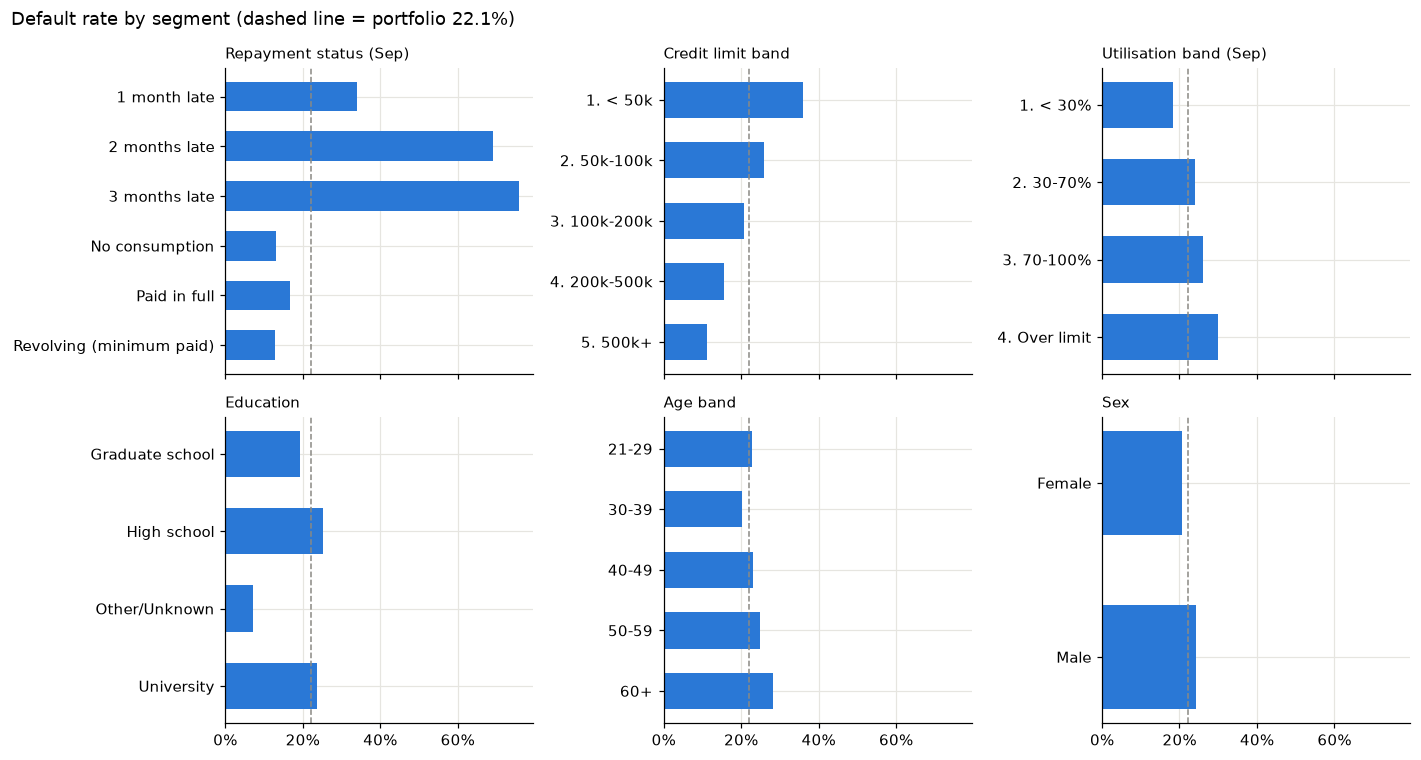

In [5]:
order = ["Repayment status (Sep)", "Credit limit band", "Utilisation band (Sep)",
         "Education", "Age band", "Sex"]
portfolio = profile["default_next_month"].mean()
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, seg_type in zip(axes.flat, order):
    d = seg[seg["segment_type"] == seg_type].sort_values("segment_value")
    ax.barh(d["segment_value"], d["default_rate"], color=BLUE, height=0.6)
    ax.axvline(portfolio, color=GRAY, linestyle="--", linewidth=1)
    ax.set_title(seg_type, loc="left", fontsize=10)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.suptitle(f"Default rate by segment (dashed line = portfolio {portfolio:.1%})", x=0.01, ha="left")
fig.tight_layout()

Low limits look risky. Is that just because small limits get maxed out? Crossing limit with utilisation:

In [6]:
heat = profile.pivot_table(index="credit_limit_band", columns="utilisation_band",
                            values="default_next_month", aggfunc="mean")
heat.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None)

utilisation_band,1. < 30%,2. 30-70%,3. 70-100%,4. Over limit
credit_limit_band,,,,
1. < 50k,35.4%,40.9%,34.0%,35.1%
2. 50k-100k,24.4%,27.2%,25.1%,30.5%
3. 100k-200k,19.1%,21.0%,22.7%,26.2%
4. 200k-500k,14.6%,12.8%,20.5%,28.3%
5. 500k+,10.4%,5.4%,21.1%,44.4%


Customers under 50k default at 34 to 41% at **every** utilisation level, so a low limit carries risk on its
own. A low limit is partly the bank's earlier risk judgement, so this is a signal rather than a cause. High-limit
customers only become risky when they run close to or over the limit.

## 3. Behaviour in the months before default

First attempt: delinquency defined as 1+ month late.

In [7]:
monthly["outcome"] = np.where(monthly["default_next_month"] == 1, "Defaulted in Oct", "Did not default")
trend = (monthly.groupby(["month_order", "month_label", "outcome"])
         .agg(late_1plus=("is_delinquent", "mean"), late_2plus=("is_delinquent_2plus", "mean"),
              utilisation=("utilisation", "mean"))
         .reset_index())

counts = monthly.pivot_table(index="month_label", columns="months_delayed", values="customer_id",
                             aggfunc="count", fill_value=0)
counts.loc[trend.sort_values("month_order")["month_label"].unique(), [1, 2, 3]]

months_delayed,1,2,3
month_label,,,
Apr 2005,0,2766,184
May 2005,0,2626,178
Jun 2005,2,3159,180
Jul 2005,4,3819,240
Aug 2005,28,3927,326
Sep 2005,3688,2667,322


"1 month late" barely exists before September (0 to 28 customers a month, then 3,688 in Sep).
That points to a change in how the status was coded, not a real jump in arrears. A 1+ definition
would show a spike in September that isn't real, so trends use **2+ months late**, which is coded
consistently. Even that looks different in Sep, so I read the trend on Apr to Aug.

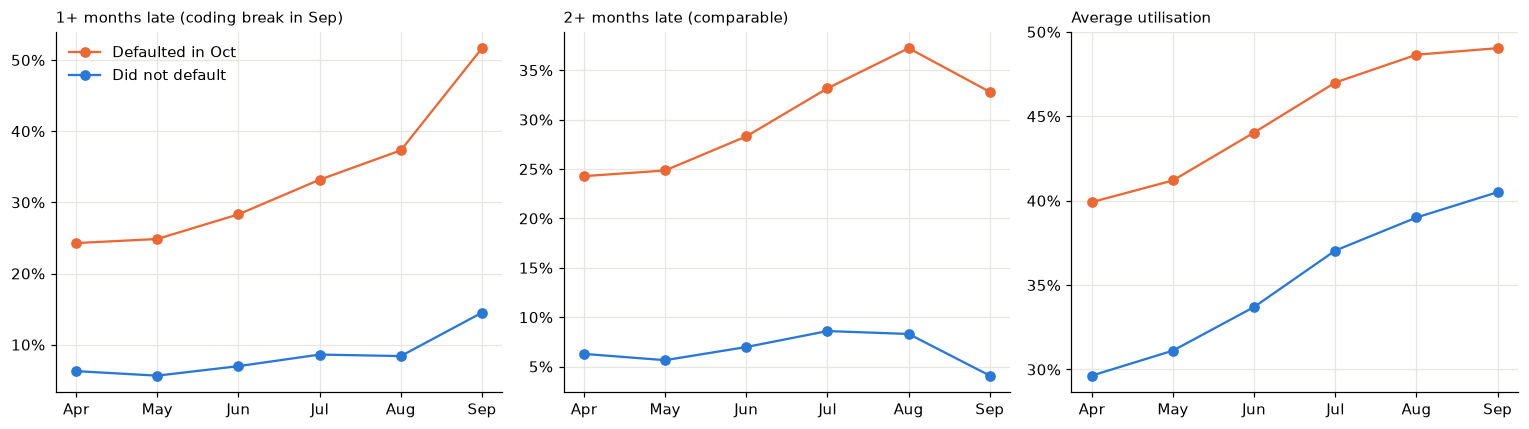

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (col, title) in zip(axes, [("late_1plus", "1+ months late (coding break in Sep)"),
                                   ("late_2plus", "2+ months late (comparable)"),
                                   ("utilisation", "Average utilisation")]):
    for outcome, color in [("Defaulted in Oct", ORANGE), ("Did not default", BLUE)]:
        d = trend[trend["outcome"] == outcome].sort_values("month_order")
        ax.plot(d["month_label"].str[:3], d[col], marker="o", color=color, label=outcome)
    ax.set_title(title, loc="left", fontsize=10)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].legend(frameon=False)
axes[2].yaxis.set_major_locator(plt.MultipleLocator(0.05))
fig.tight_layout()

Future defaulters drift away from everyone else months in advance: 24% are 2+ months late in April,
37% in August, while non-defaulters stay around 6 to 8%. Utilisation rises for both groups but stays about
10 points higher for defaulters.

### Roll rates: once behind, do customers catch up?

In [9]:
roll = sql("SELECT * FROM analytics.vw_roll_rates")
roll["roll_rate"] = roll["roll_rate"].astype(float)
roll.pivot(index="from_bucket", columns="to_bucket", values="roll_rate").style.format("{:.1%}")

to_bucket,1. Up to date,2. 1-2 months late,3. 3+ months late
from_bucket,,,
1. Up to date,95.1%,4.9%,nan%
2. 1-2 months late,30.2%,63.7%,6.1%
3. 3+ months late,10.4%,31.9%,57.7%


Arrears are sticky: of customers 1 to 2 months behind, only 30% are up to date the next month.
For a collections team that means a first missed payment is the moment to act.

## 4. Things to carry into modelling

In [10]:
inactive = profile["total_billed_6m"] <= 0
pd.DataFrame({
    "customers": [inactive.sum(), (~inactive).sum()],
    "default_rate": [profile.loc[inactive, "default_next_month"].mean(),
                     profile.loc[~inactive, "default_next_month"].mean()],
}, index=["No bills in 6 months", "Active"])

,customers,default_rate
No bills in 6 months,1071,0.344
Active,28929,0.217


- Cards with no positive balance in six months (1,071 customers, of which 866 have only zero bills) still default at 34%. That's a known quirk of this dataset; I keep these
  customers and give the model an `inactive_6m` flag instead of dropping them.
- Behaviour features (months late, latest status, utilisation, payment ratio) carry the signal; demographics add little.
  That supports leaving sex and marital status out of the model, which I test explicitly in `src/train_model.py`.
- All features are observed by the end of September and the target is October, so there's no leakage.